In [6]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

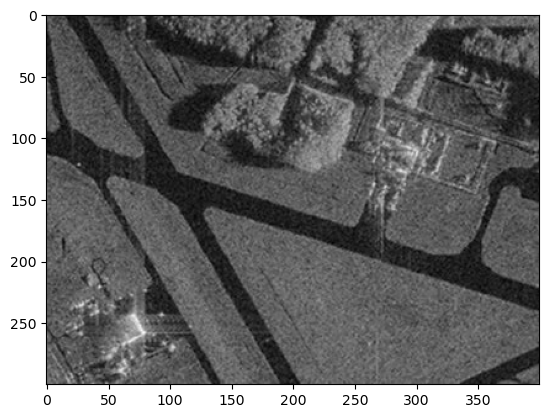

In [7]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 
plt.imshow(image_gray, cmap="gray")

# Алгоритм разрастания регионов

In [49]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
                                                            
    if abs(av_val - img[point]) <= T:
        return True
    
    return False    

In [3]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask
        
    return mask*255

In [6]:
seed_point = (250,250)
mask = region_growing(image_gray,seed_point,homo_average, 7, 20)

184
525
845
1190
1515
1842
1517
1581
1467
1339
1228
1137
1103
1273
1338
1495
1474
1614
1903
1769
1509
1580
1521
1617
1720
2378
2181
1960
1465
1577
1482
1521
1784
1678
1619
1753
2392
1813
1649
1813
1523
465
384
393
456
497
490
469
402
534
632
650
434
343
341
379
397
366
234
108
68
11
0


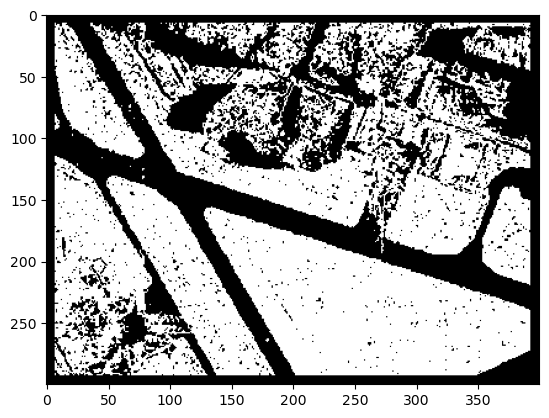

In [7]:
plt.imshow(mask, cmap="gray")

# Сравнение критериев однородности

In [30]:
def homo_local(img, mask, point, T):
    i, j = point
    r = 2
    
    neighborhood = img[max(0, i-r):i+r+1, max(0, j-r):j+r+1]
    av_val = neighborhood.mean()
    
    if abs(av_val - img[point]) <= T:
        return True
    
    return False

154
389
649
933
1160
1428
1166
1240
1410
1511
1554
1732
1830
1947
1957
2099
2229
2241
2435
2478
1984
1806
1848
1777
1737
1791
1832
1944
1954
2040
2072
2137
2085
2217
2188
2403
2449
2509
2495
2414
1232
13
0


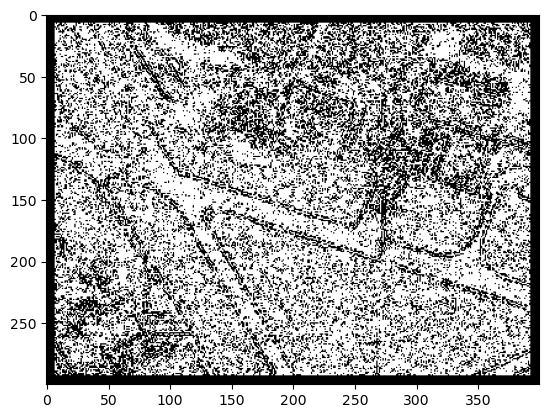

In [31]:
seed_point = (250, 250)
mask_local = region_growing(image_gray, seed_point, homo_local, 7, 8)
plt.imshow(mask_local, cmap="gray")

Алгоритм homo_average значительно лучше. Число пикселей на результатах работы двух алгоритмов схожее (71927 и 73469), но качество разное. Алгоритм homo_local дал зашумленную маску - внутри региона оказалось множество пропусков. А homo_average выделил газон монолитной областью с четкими границами.

# Алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев

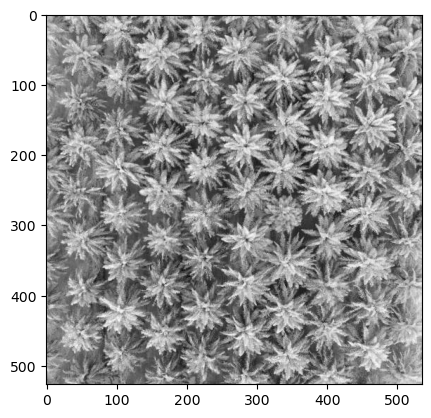

In [41]:
image = cv2.imread('palm_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")

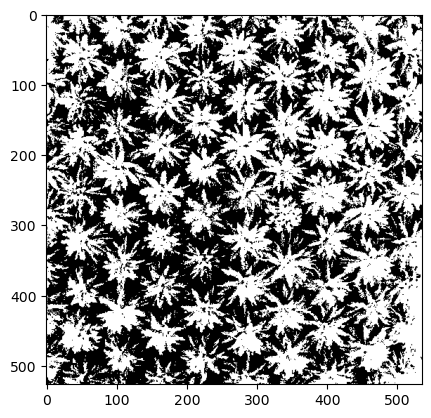

In [42]:
ret, thresh = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)
plt.imshow(thresh, cmap="gray")

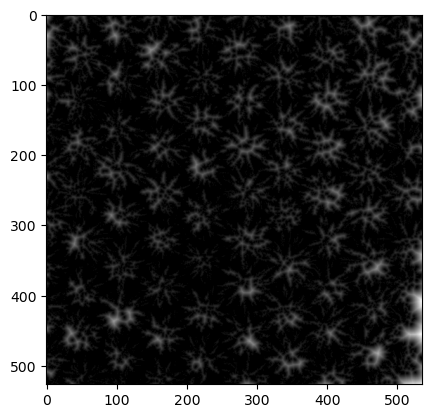

In [43]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5) 
plt.imshow(dist, cmap="gray")

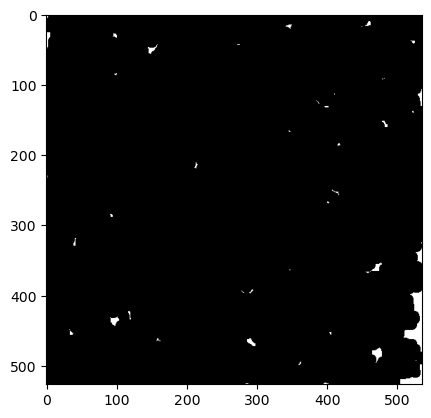

In [44]:
ret, sure_fg = cv2.threshold(dist, 0.4 * dist.max(), 255, cv2.THRESH_BINARY) 
plt.imshow(sure_fg, cmap="gray")

In [45]:
sure_fg = sure_fg.astype(np.uint8)
ret, markers = cv2.connectedComponents(sure_fg) 
print("Предварительное число пальм:", ret - 1)

Предварительное число пальм: 52


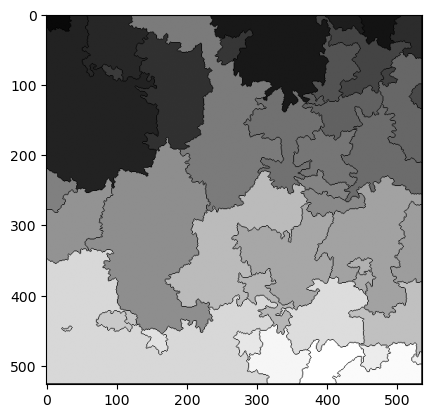

In [46]:
markers = cv2.watershed(image, markers)
plt.imshow(markers, cmap="gray")

In [47]:
print("Итоговое число пальм:", markers.max())

Итоговое число пальм: 51
